# Jour 4 : analyse

Trois visualisations sur les données nettoyées et transformées (`jour_3`) : profil horaire du débit (semaine / week-end), heatmap de l'occupation par jour et heure, diagramme fondamental. Le débit étant recopié sur plusieurs capteurs, il est compté une seule fois par série (`q_unique`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("./data/processed/comptages_apres_transformation_statistiques.csv")
Path("figures").mkdir(exist_ok=True)


In [2]:
df.head()

,t_1h,iu_ac,libelle,q,k,etat_trafic,iu_nd_amont,iu_nd_aval,t_1h_paris,heure,jour_semaine,nom_jour,weekend,mois,congestion,barre_Ouvert,groupe_q,aberrant_iqr
0,2026-03-01 00:00:00+00:00,317,Quai_d'Orsay,381.0,1.48278,Fluide,187,186,2026-03-01 01:00:00+01:00,1,7,Dimanche,oui,3,0.0,1,9011029950719288860,False
1,2026-03-01 01:00:00+00:00,317,Quai_d'Orsay,309.0,1.37667,Fluide,187,186,2026-03-01 02:00:00+01:00,2,7,Dimanche,oui,3,0.0,1,9011029950719288860,False
2,2026-03-01 02:00:00+00:00,317,Quai_d'Orsay,251.0,1.17333,Fluide,187,186,2026-03-01 03:00:00+01:00,3,7,Dimanche,oui,3,0.0,1,9011029950719288860,False
3,2026-03-01 03:00:00+00:00,317,Quai_d'Orsay,186.0,0.80278,Fluide,187,186,2026-03-01 04:00:00+01:00,4,7,Dimanche,oui,3,0.0,1,9011029950719288860,False
4,2026-03-01 04:00:00+00:00,317,Quai_d'Orsay,135.0,0.66223,Fluide,187,186,2026-03-01 05:00:00+01:00,5,7,Dimanche,oui,3,0.0,1,9011029950719288860,False


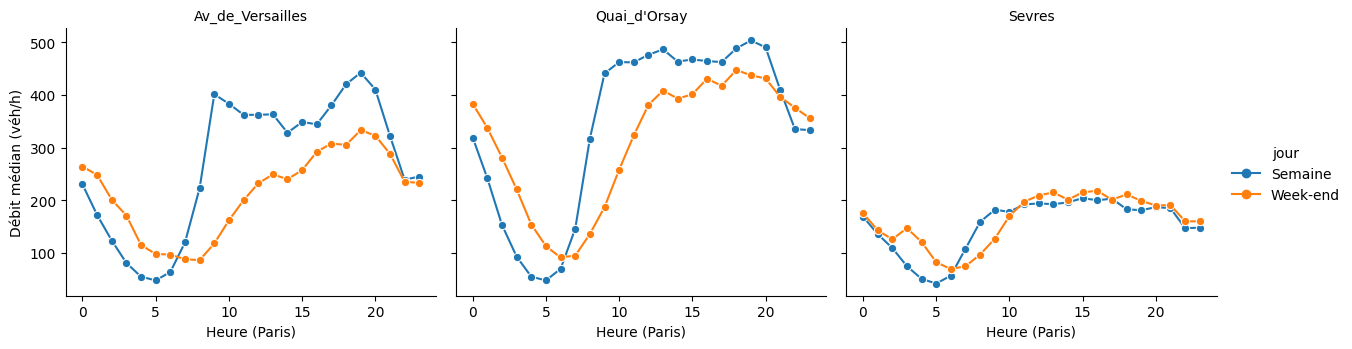

In [3]:
# Une copie par série de débit, avec le type de jour
q_unique = df.dropna(subset=["q"]).drop_duplicates(["groupe_q", "t_1h"]).copy()
q_unique["jour"] = np.where(q_unique["weekend"] == "oui", "Week-end", "Semaine")

# Débit médian par axe, type de jour et heure
profil = (q_unique.groupby(["libelle", "jour", "heure"], observed=True)["q"]
          .median().reset_index())

g = sns.relplot(
    data=profil, x="heure", y="q",
    hue="jour", hue_order=["Semaine", "Week-end"],
    col="libelle", kind="line", marker="o",
    height=3.6, aspect=1.15,
)
g.set_titles("{col_name}")
g.set_axis_labels("Heure (Paris)", "Débit médian (véh/h)")
g.savefig("figures/04_profil_horaire_semaine_weekend.png", dpi=150, bbox_inches="tight")
plt.show()

**Profil horaire du débit médian (semaine vs week-end)**

Comme on peut le constater sur les 3 axes, il ya un creux nocture et le débit de semaine tombe à son minimum vers 5h (en dessus de 100 véhicule par heure.) Cela peut s'expliquer par le fait que à cette heure les usages qui sont censé etre des travailleurs sont encore au lit. 
- **Av_de_Versailles** : en semaine, le débit saute entre 8 h et 9 h (de 220 à 400 véh/h environ), reste sur un plateau autour de 350 à 360 véh/h jusqu'à 15 h, puis atteint son maximum vers 19 h (environ 440 véh/h). Le week-end, la montée est plus lente et le maximum plus bas (environ 330 véh/h vers 19 h).
- **Quai_d'Orsay** : c'est l'axe le plus chargé par le fait que c'est la rue qui est proche de la tour eifeil, musée du Louvres, l'assemblée nationale etc. Donc elle est utilisée par les travailleurs ainsi que des touristes visiteurs Le débit de semaine monte brutalement vers 9 h, puis reste entre 460 et 500 véh/h de 10 h à 20 h, avec un maximum vers 19 h (environ 500 véh/h). Il n'y a pas de pointe marquée, c'est un plateau de journée.
- **Sevres** : le profil est plat (environ 180 à 210 véh/h de 9 h à 20 h) et l'écart semaine / week-end est faible.
- **Nuit du week-end** : entre 0 h et 3 h, le débit est plus élevé le week-end qu'en semaine sur Versailles et Orsay (par exemple environ 385 contre 320 véh/h à 0 h sur le Quai d'Orsay). On observe des déplacements de soirée et de retour de sortie.

Le débit seul ne dit pas s'il y a congestion : Sevres a le plus faible débit mais l'occupation médiane la plus élevée (5,5 % en moyenne). C'est ce que le diagramme fondamental permettra de distinguer.

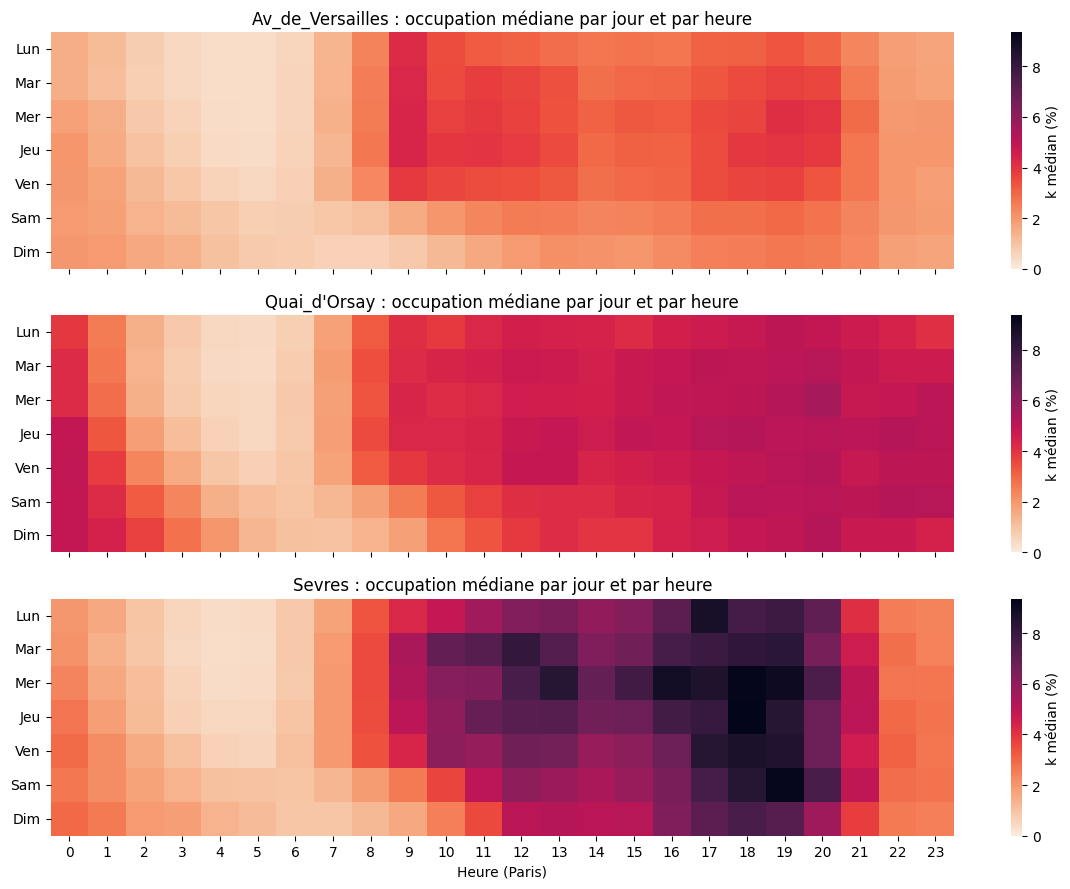

In [4]:
JOURS_COURTS = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
axes_noms = sorted(df["libelle"].unique())

# Occupation médiane par axe : lignes = jour, colonnes = heure
tables = {
    axe: (df[df["libelle"] == axe]
          .pivot_table(index="jour_semaine", columns="heure",
                       values="k", aggfunc="median"))
    for axe in axes_noms
}

vmax = max(t.max().max() for t in tables.values())   # échelle commune

fig, axes = plt.subplots(len(axes_noms), 1, figsize=(12, 9), sharex=True)
for ax, axe in zip(axes, axes_noms):
    t = tables[axe]
    t.index = JOURS_COURTS
    sns.heatmap(t, cmap="rocket_r", vmin=0, vmax=vmax, ax=ax,
                cbar_kws={"label": "k médian (%)"})
    ax.set_title(f"{axe} : occupation médiane par jour et par heure")
    ax.set_xlabel("")
    ax.set_ylabel("")
axes[-1].set_xlabel("Heure (Paris)")
plt.tight_layout()
plt.savefig("figures/05_heatmap_occupation.png", dpi=150, bbox_inches="tight")
plt.show()

L'échelle de couleurs est commune aux trois axes, ce qui permet de les comparer directement.

- **Sevres** est l'axe le plus occupé et le plus contrasté. En semaine, l'occupation médiane dépasse 6 % de 10 h à 20 h et atteint son maximum (environ 8 à 9 %) en fin de journée, vers 17 h-19 h, surtout du mercredi au vendredi. Le samedi montre aussi un point chaud vers 19 h. Le dimanche reste plus clair.
- **Av_de_Versailles** a une pointe nette le matin, vers 9 h, du lundi au jeudi (médiane de 4,2 % en jours ouvrés), puis un plateau de 2 à 4 % jusqu'au soir, avec un second pic vers 18 h-19 h. Le week-end, l'occupation reste faible (environ 2 à 3 %) et il n'y a pas de pointe du matin.
- **Quai_d'Orsay** est occupé presque toute la journée, sans pointe marquée : environ 4 à 6 % de 10 h à 23 h, avec un maximum vers 19 h-20 h (5,2 %). Le week-end ressemble à la semaine en fin de journée. L'occupation reste élevée tard le soir : le jeudi, le vendredi, le samedi et le dimanche, elle est déjà autour de 5 % à minuit.
- **Creux commun** : sur les trois axes, l'occupation est minimale entre 3 h et 6 h (moins de 1 à 2 %).

Le jour compte surtout à Versailles (pointe du matin de semaine absente le week-end). À Sevres, la congestion se concentre sur la fin d'après-midi en semaine. À Orsay, l'heure compte plus que le jour.

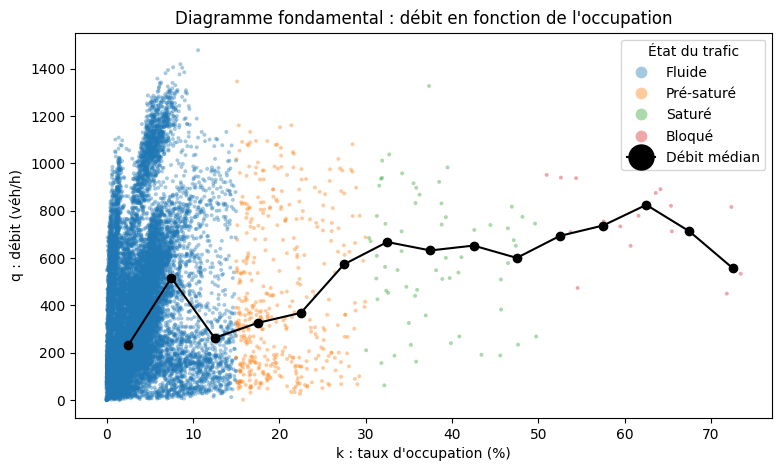

k
(0, 5]      232.0
(5, 10]     517.0
(10, 15]    263.0
(15, 20]    326.0
(20, 25]    369.0
(25, 30]    574.0
(30, 35]    668.0
(35, 40]    632.0
(40, 45]    653.0
(45, 50]    601.0
(50, 55]    694.0
(55, 60]    738.0
(60, 65]    825.0
(65, 70]    713.0
(70, 75]    558.0


In [5]:
# Données : une copie par série de débit, sans l'état Inconnu
d = q_unique.dropna(subset=["q", "k"])
d = d[d["etat_trafic"] != "Inconnu"].copy()

# Échantillon pour le nuage (sinon trop lourd et illisible)
echantillon = d.sample(min(20_000, len(d)), random_state=0)
ordre = ["Fluide", "Pré-saturé", "Saturé", "Bloqué"]

# Débit médian par classe d'occupation (tranches de 5 points)
classes = pd.cut(d["k"], bins=range(0, 101, 5))
mediane = d.groupby(classes, observed=True)["q"].median()
milieux = [c.mid for c in mediane.index]

plt.figure(figsize=(9, 5))
sns.scatterplot(data=echantillon, x="k", y="q",
                hue="etat_trafic", hue_order=ordre,
                s=8, alpha=0.4, linewidth=0)
plt.plot(milieux, mediane.values, color="black", marker="o",
         label="Débit médian")
plt.title("Diagramme fondamental : débit en fonction de l'occupation")
plt.xlabel("k : taux d'occupation (%)")
plt.ylabel("q : débit (véh/h)")
plt.legend(title="État du trafic", markerscale=3)
plt.savefig("figures/06_diagramme_fondamental.png", dpi=150, bbox_inches="tight")
plt.show()

# Pour lire les valeurs de la courbe médiane dans le markdown
print(mediane.round(0).to_string())

**Diagramme fondamental : débit en fonction de l'occupation**

Les couleurs forment des bandes verticales nettes : l'état du trafic est un simple découpage de `k` (Fluide < 15 %, Pré-saturé 15-30 %, Saturé 30-50 %, Bloqué > 50 %), pas une information indépendante.

- **Occupation faible (k < 15 %)** : c'est là que se concentre l'essentiel des mesures. Le débit y varie de 0 à près de 1 400 véh/h pour une même occupation, et plusieurs « traînées » verticales apparaissent autour de k = 5-8 %. Elles correspondent à des capteurs différents, dont les niveaux de débit ne sont pas comparables.
- **Courbe médiane** : le débit médian passe de 232 véh/h (k de 0 à 5 %) à 517 véh/h (k de 5 à 10 %), retombe à 263 véh/h (10-15 %), puis monte de façon régulière jusqu'à 668 véh/h (30-35 %). Il reste ensuite entre 600 et 700 véh/h jusqu'à 55 %, et atteint son maximum de 825 véh/h dans la tranche 60-65 %, avant de redescendre à 713 véh/h (65-70 %) et 558 véh/h (70-75 %).
- **Au-delà de k = 30 %**, les points sont rares sur le nuage (peu de mesures Saturé et Bloqué) : la médiane y est instable, et son maximum à 60-65 % ne doit pas être présenté comme un seuil de saturation.
- **Lecture** : à occupation élevée, le débit ne progresse plus et finit par baisser. Plus de véhicules sur le capteur ne signifie pas plus de véhicules qui passent, c'est la congestion. Un même débit peut donc correspondre à un trafic fluide ou saturé, et c'est l'occupation qui les distingue.